#### Import relevant libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Load dataset and subset columns

In [2]:
houseprice_data = pd.read_csv("data/HousingPricesData.csv")

In [3]:
houseprice_data = houseprice_data[['Price', 'Area', 'Room']]

#### Inspect first 5 rows and data types of the dataset

In [4]:
houseprice_data.head()

,Price,Area,Room
0,685000.0,64,3
1,475000.0,60,3
2,850000.0,109,4
3,580000.0,128,6
4,720000.0,138,5


In [5]:
houseprice_data.shape

(924, 3)

#### Generate Summary Statistics

In [6]:
houseprice_data.describe().apply(lambda s: s.apply('{0:.1f}'.format))

,Price,Area,Room
count,920.0,924.0,924.0
mean,622065.4,96.0,3.6
std,538994.2,57.4,1.6
min,175000.0,21.0,1.0
25%,350000.0,60.8,3.0
50%,467000.0,83.0,3.0
75%,700000.0,113.0,4.0
max,5950000.0,623.0,14.0


#### Identify bivariate outliers using Scatter plot 

Text(0.5, 1.0, 'Bivariate Outlier Analysis of House prices and Area')

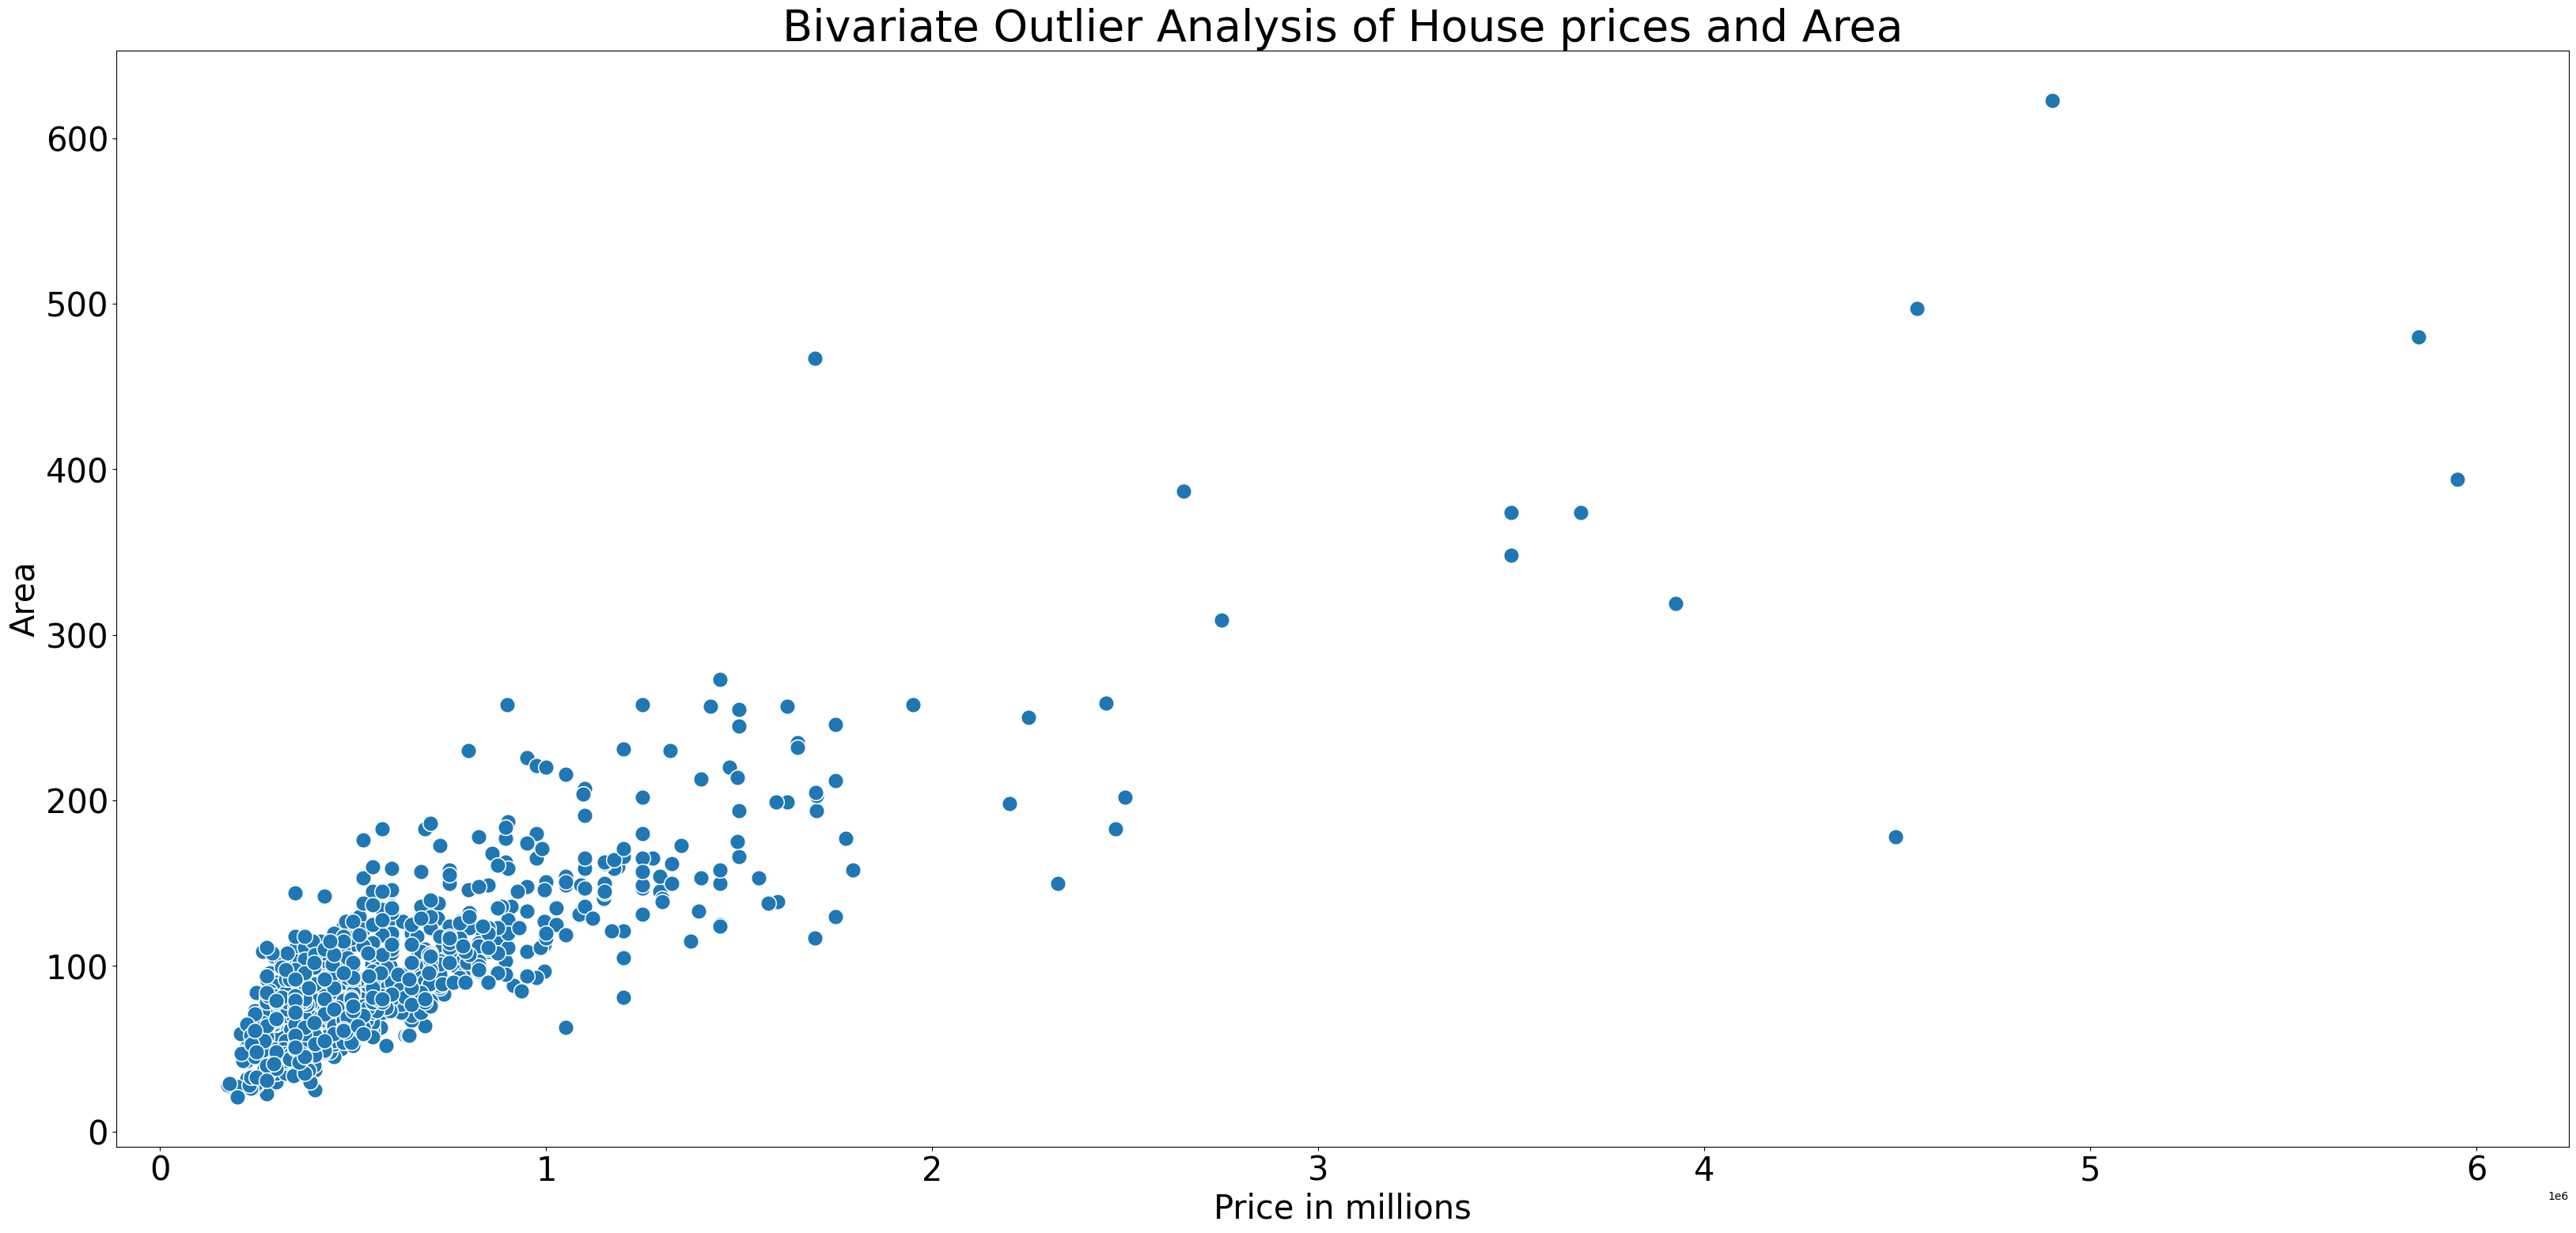

In [7]:
plt.figure(figsize = (40,18))

ax = sns.scatterplot(data= houseprice_data, x= 'Price', y = 'Area',s = 200)
ax.set_xlabel('Price in millions', fontsize = 30)
ax.set_ylabel('Area',  fontsize = 30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)

ax.set_title('Bivariate Outlier Analysis of House prices and Area', fontsize = 40)


#### Identify bivariate outliers using Boxplot

Text(0.5, 1.0, 'Bivariate Outlier Analysis of House prices and Rooms')

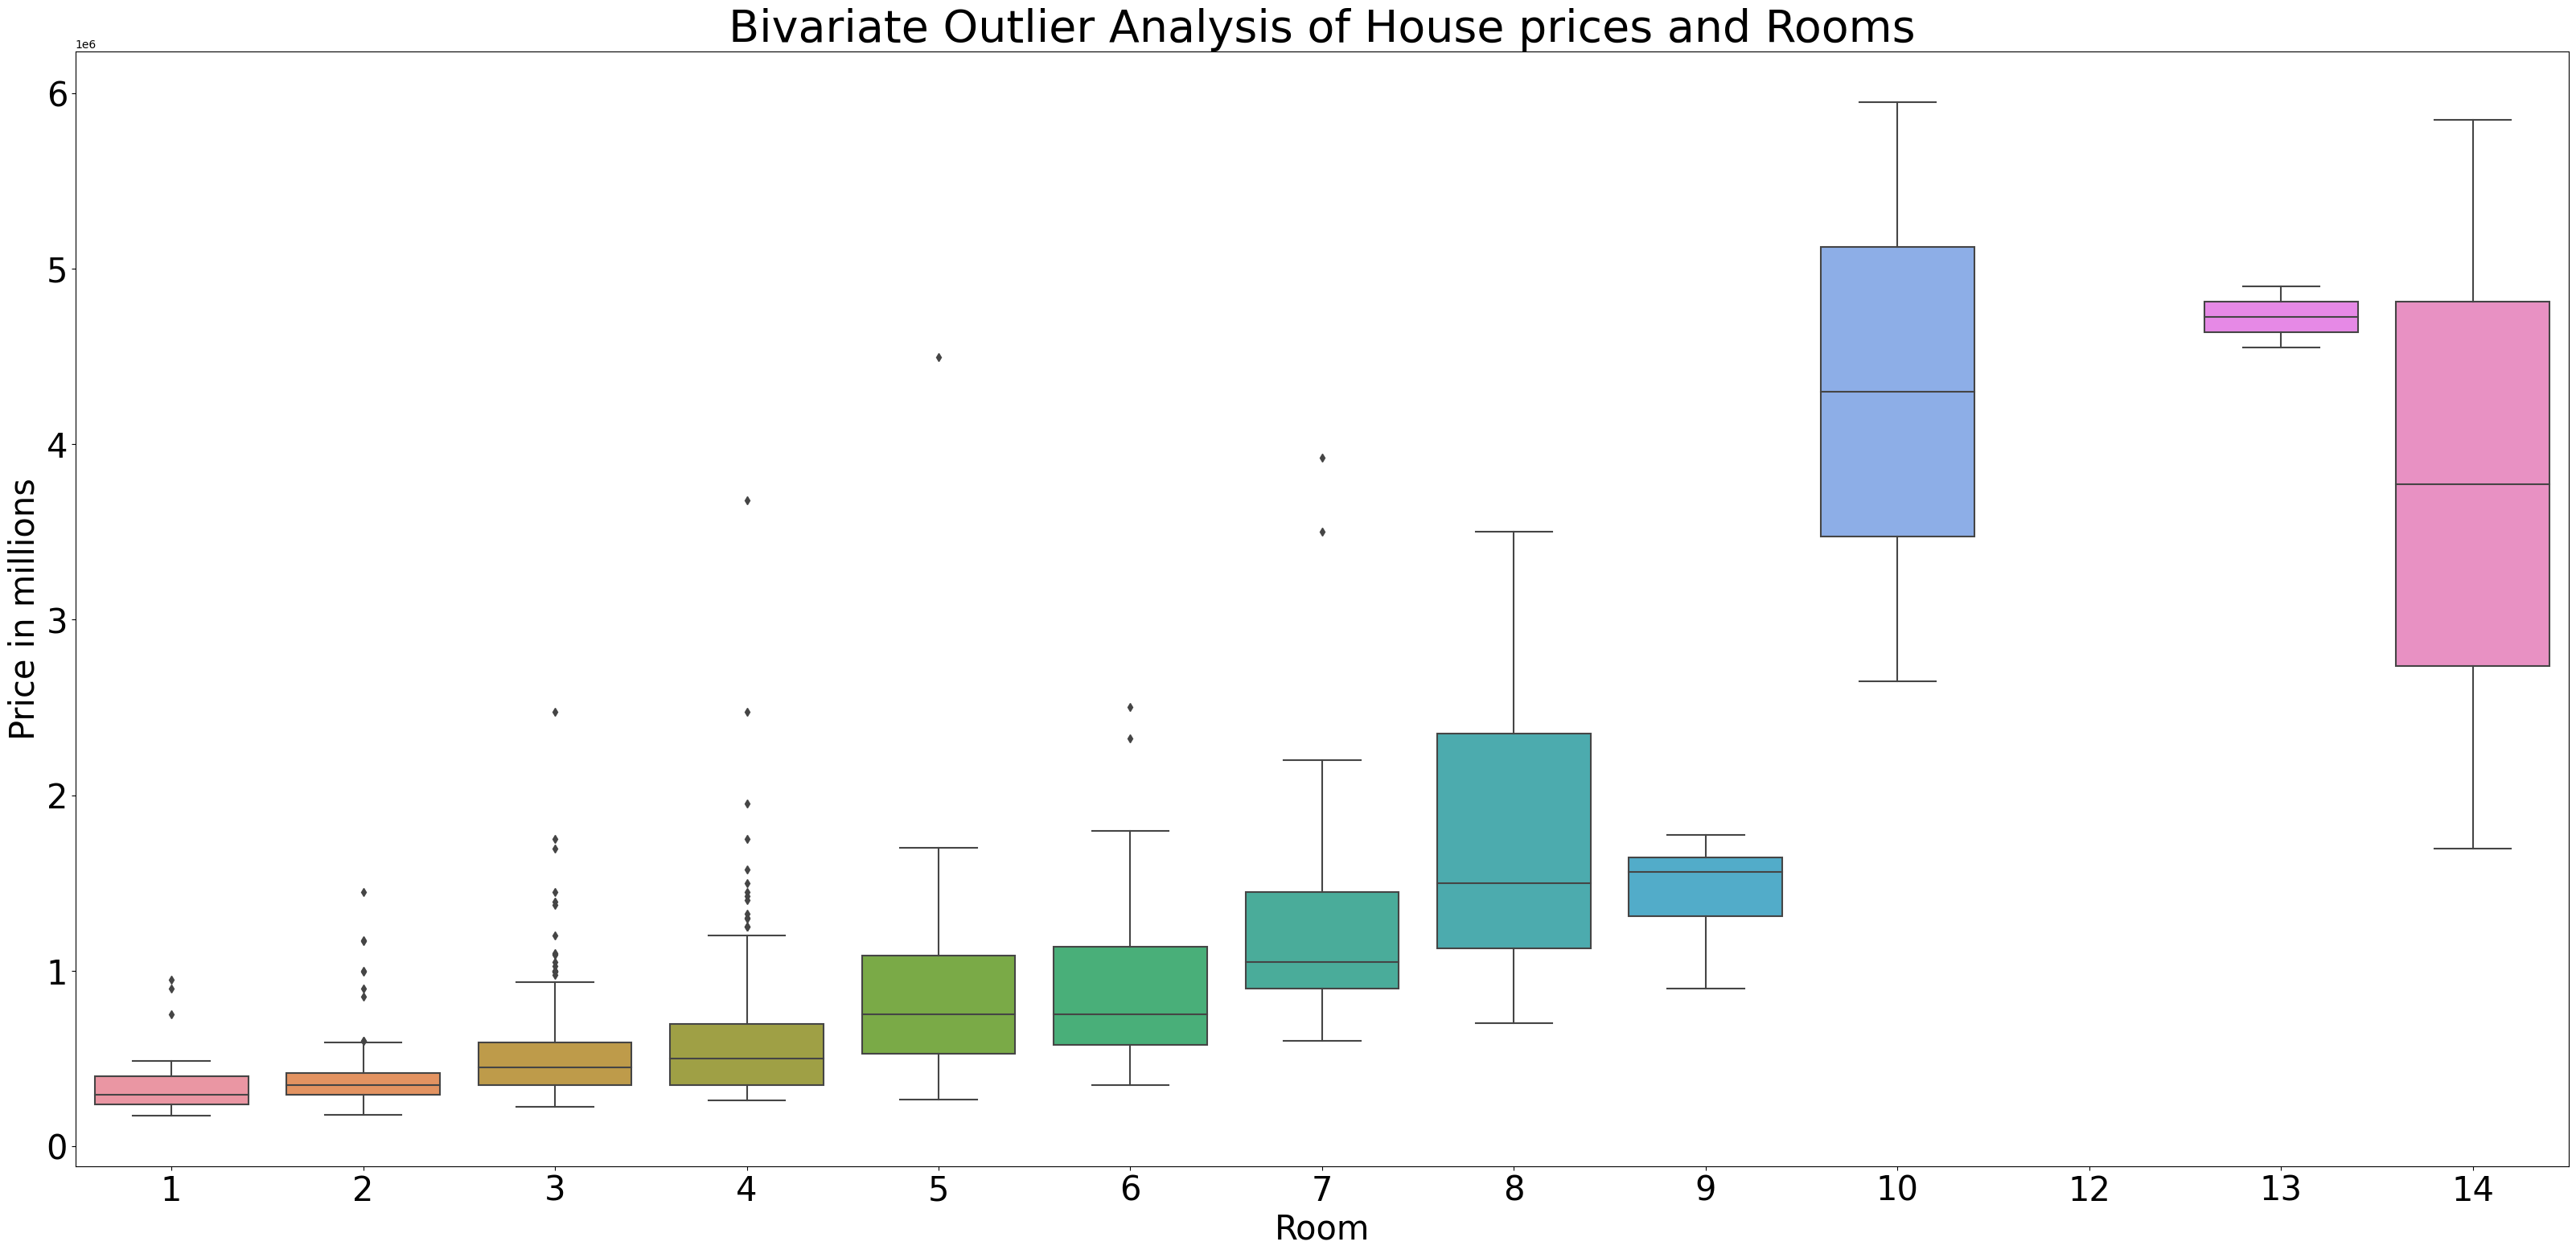

In [8]:
plt.figure(figsize = (40,18))

ax = sns.boxplot(data= houseprice_data,x = 'Room', y= 'Price')
ax.set_xlabel('Room', fontsize = 30)
ax.set_ylabel('Price in millions',  fontsize = 30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
ax.set_title('Bivariate Outlier Analysis of House prices and Rooms', fontsize = 40)

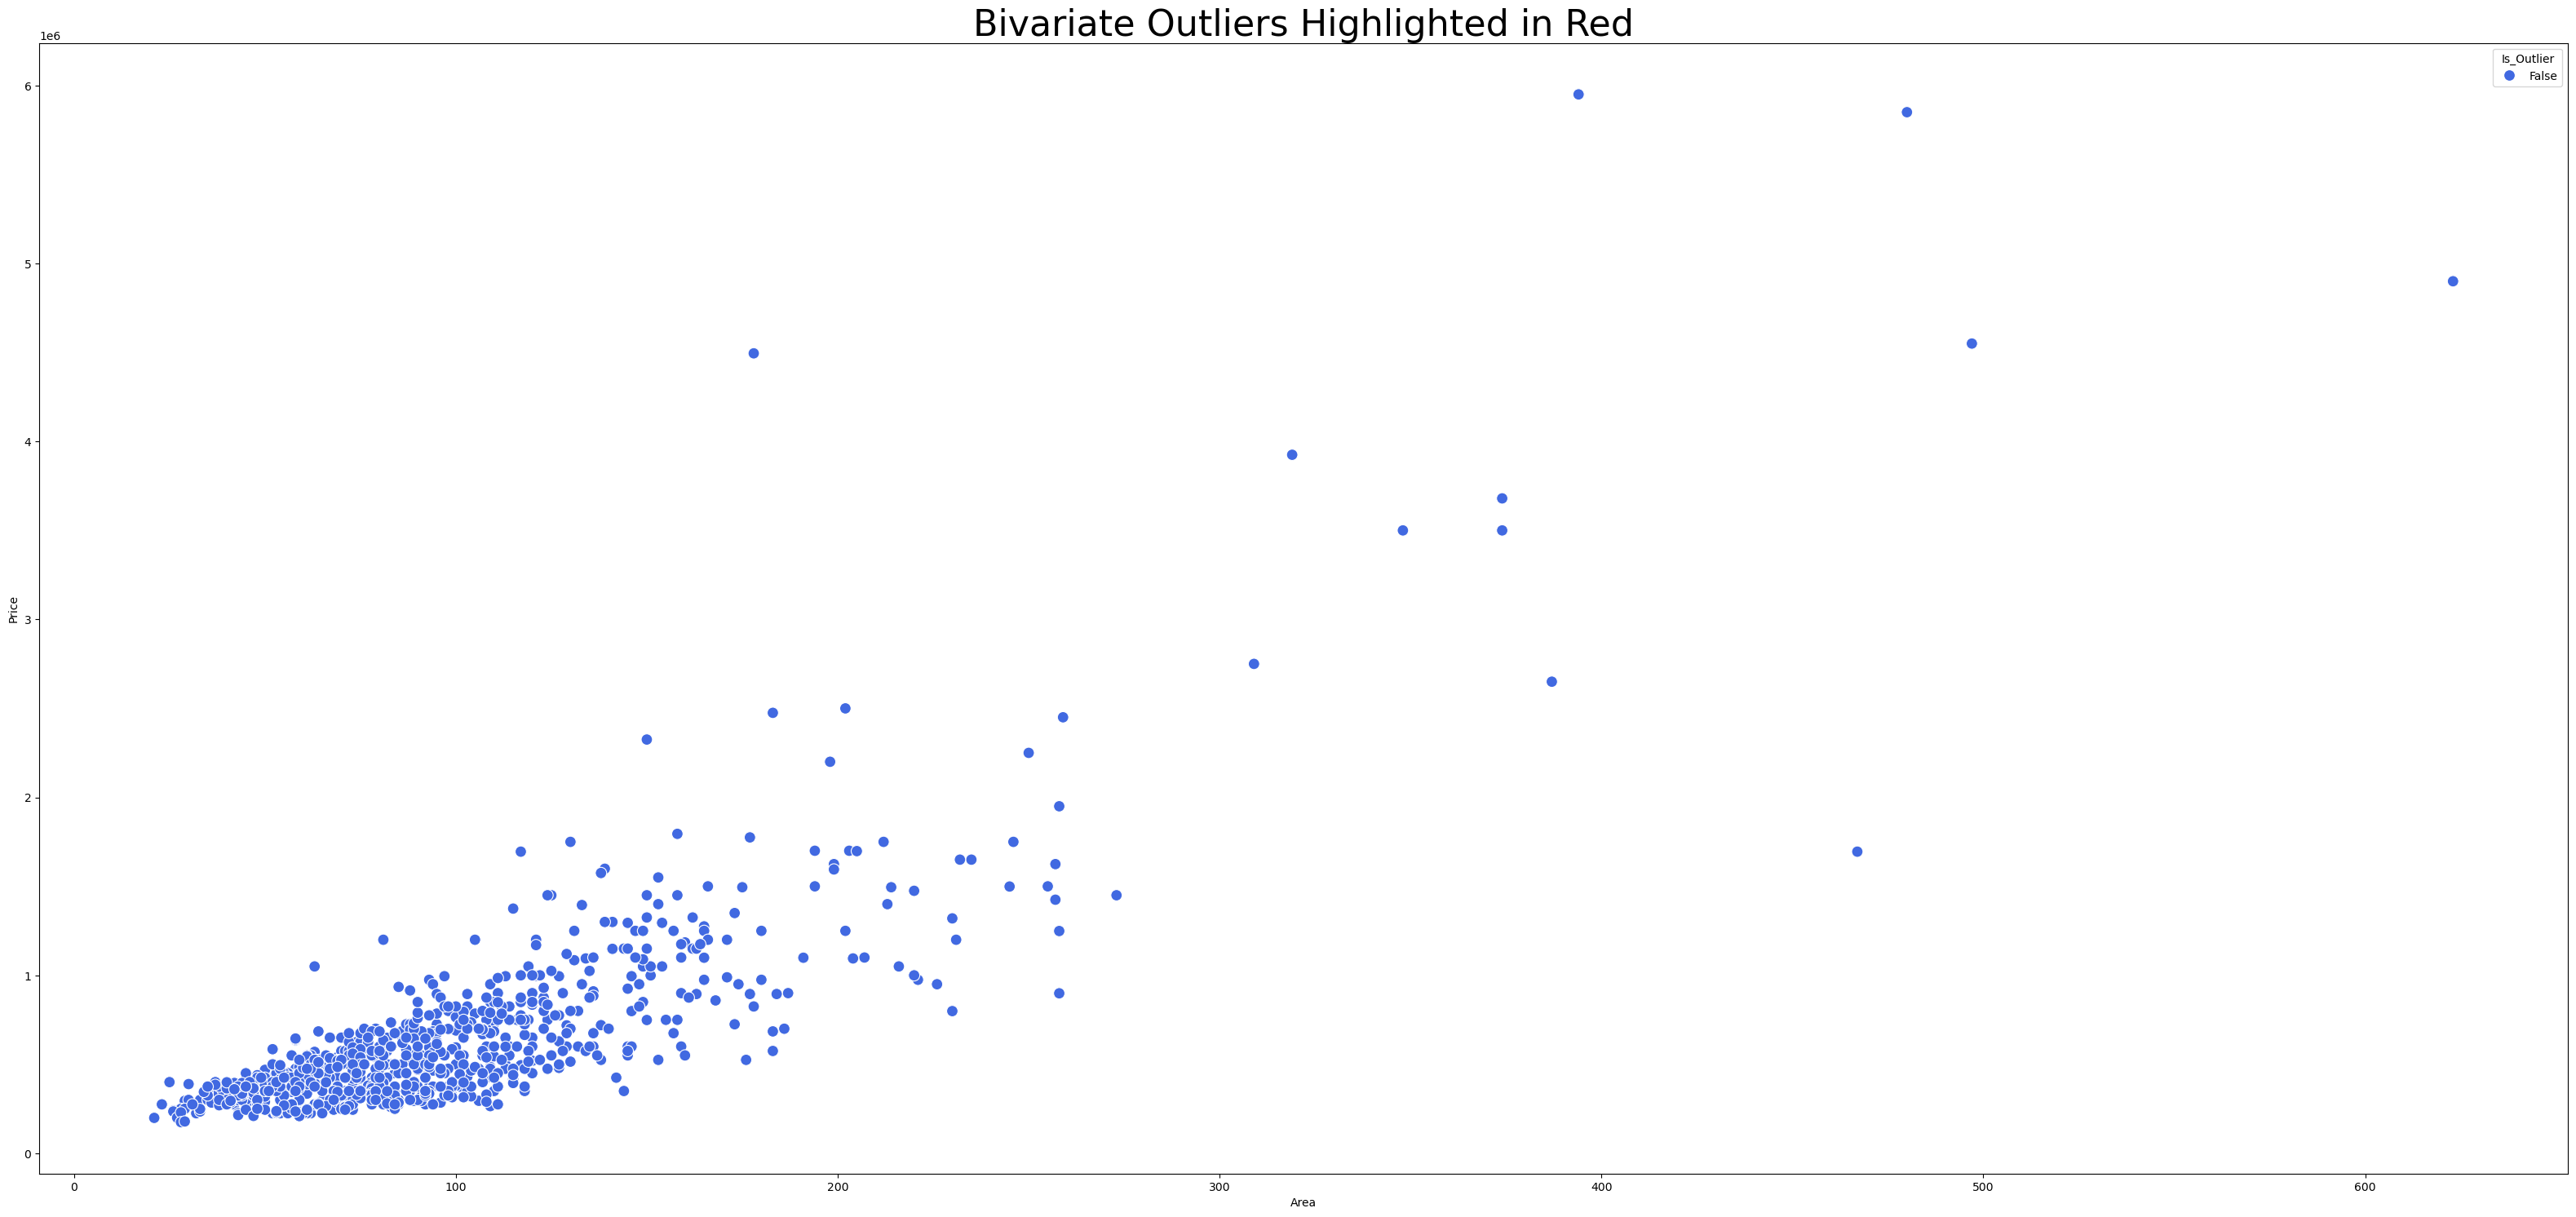

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2

#Mahalanobis Distance (Best for Linear Trends)
#Mahalanobis distance measures how many standard deviations a point is away from the center of the data cloud, 
#accounting for the direction and correlation of the data
houseprice_data = pd.read_csv("data/HousingPricesData.csv")

# 1. Select the two columns you are plotting
X = houseprice_data[['Area', 'Price']].values
data_mu = np.mean(X, axis=0)
covariance = np.cov(X.T)
inv_covariance = np.linalg.inv(covariance)

# 2. Calculate distance for every single point
distances = []
for i in range(len(X)):
    diff = X[i] - data_mu
    distance = np.dot(np.dot(diff, inv_covariance), diff.T)
    distances.append(distance)

# 3. Use Chi-Square cutoff threshold (e.g., 97.5% confidence limit)
cutoff = chi2.ppf(0.975, df=2)
houseprice_data['Is_Outlier'] = np.array(distances) > cutoff

# 4. Plot and highlight them instantly using Seaborn's 'hue'
plt.figure(figsize=(40, 18))
sns.scatterplot(
    data=houseprice_data, 
    x='Area', 
    y='Price', 
    hue='Is_Outlier', 
    palette={False: 'royalblue', True: 'crimson'}, 
    s=100
)
plt.title("Bivariate Outliers Highlighted in Red", fontsize=32)
plt.show()


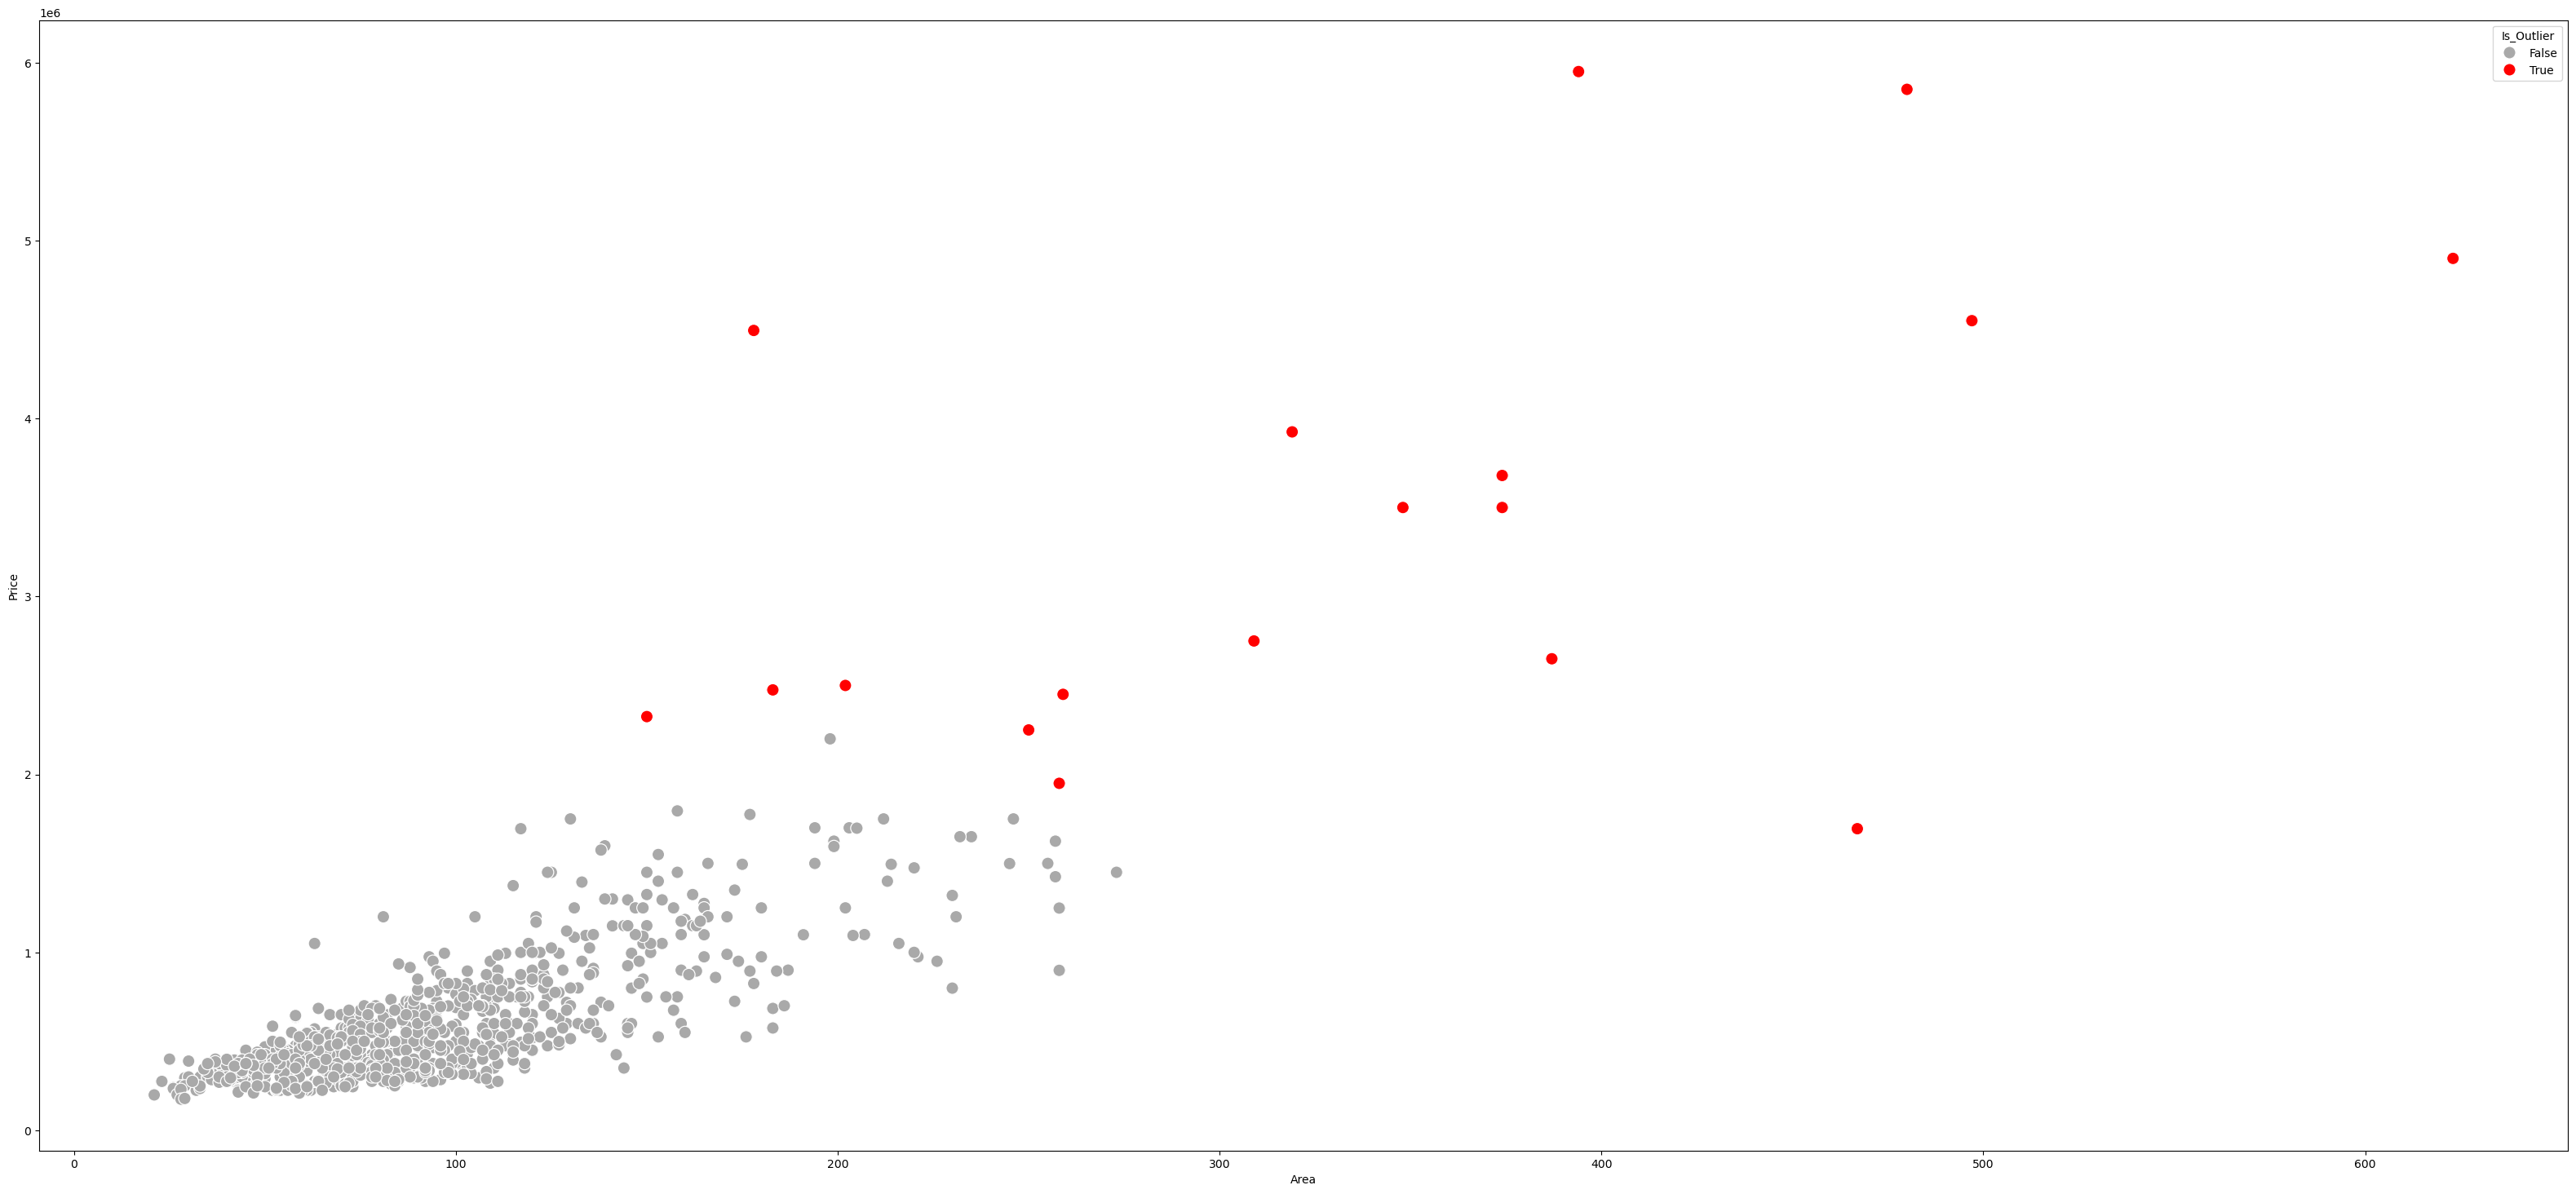

In [3]:
from sklearn.ensemble import IsolationForest

# Isolation Forest (Best for Non-Linear or Complex Shapes)
# If your data does not form a straight line (e.g., it curves or forms weird shapes), 
# use an Isolation Forest from scikit-learn. It isolates outliers by randomly partitioning the dataset.
houseprice_data = pd.read_csv("data/HousingPricesData.csv")

# 1. Initialize and fit the model (assume roughly 2% of data are outliers)
iso_forest = IsolationForest(contamination=0.02, random_state=42)
houseprice_data['Outlier_Label'] = iso_forest.fit_predict(houseprice_data[['Area', 'Price']])

# Note: -1 means outlier, 1 means normal data
houseprice_data['Is_Outlier'] = houseprice_data['Outlier_Label'] == -1

# 2. Plot the results
plt.figure(figsize=(40, 18))
sns.scatterplot(
    data=houseprice_data, 
    x='Area', 
    y='Price', 
    hue='Is_Outlier', 
    palette={False: 'darkgray', True: 'red'},
    s=120
)
plt.show()
